### Step 1: Import Necessary Libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical

### Step 2: Load and Preprocess the Dataset

For the implementation, we will use MNIST Dataset.

1. The MNIST dataset is loaded. It consists of 28x28 pixel grayscale images of handwritten digits.
2. The images are reshaped from (28, 28) to (784,) and normalized by dividing by 255.
3. The labels are converted to one-hot encoded vectors.

In [2]:
(X_train, y_train), (X_test, y_test) = mnist.load_data()

X_train = X_train.reshape(-1, 28 * 28).astype('float32') / 255
X_test = X_test.reshape(-1, 28 * 28).astype('float32') / 255

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

### Step 3: Build a Neural Network without Dropout

1. A Sequential model is created without Dropout layers.
2. The model has two hidden layers with 512 neurons each and ReLU activation.
3. The output layer has 10 neurons (one for each digit) with softmax activation.
4. The model is compiled using Adam optimizer and categorical cross-entropy loss.

In [3]:
model_without_dropout = Sequential([
    Dense(512, activation='relu', input_shape=(784,)),
    Dense(512, activation='relu'),
    Dense(10, activation='softmax')
])

model_without_dropout.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [4]:
model_without_dropout.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 512)               401920    
                                                                 
 dense_1 (Dense)             (None, 512)               262656    
                                                                 
 dense_2 (Dense)             (None, 10)                5130      
                                                                 
Total params: 669,706
Trainable params: 669,706
Non-trainable params: 0
_________________________________________________________________


### Step 4: Train the Model without Dropout

1. The model is trained for 20 epochs with a batch size of 128.
2. 20% of the training data is used for validation.
3. Training history is stored for later comparison.

In [4]:
history_without_dropout = model_without_dropout.fit(
    X_train, y_train, epochs=20, batch_size=128, validation_split=0.2, verbose=2)

Epoch 1/20
375/375 - 4s - loss: 0.2423 - accuracy: 0.9276 - val_loss: 0.1253 - val_accuracy: 0.9616 - 4s/epoch - 10ms/step
Epoch 2/20
375/375 - 3s - loss: 0.0868 - accuracy: 0.9737 - val_loss: 0.0934 - val_accuracy: 0.9713 - 3s/epoch - 7ms/step
Epoch 3/20
375/375 - 3s - loss: 0.0536 - accuracy: 0.9832 - val_loss: 0.0880 - val_accuracy: 0.9724 - 3s/epoch - 7ms/step
Epoch 4/20
375/375 - 3s - loss: 0.0388 - accuracy: 0.9879 - val_loss: 0.0753 - val_accuracy: 0.9793 - 3s/epoch - 8ms/step
Epoch 5/20
375/375 - 3s - loss: 0.0244 - accuracy: 0.9923 - val_loss: 0.0958 - val_accuracy: 0.9726 - 3s/epoch - 8ms/step
Epoch 6/20
375/375 - 3s - loss: 0.0203 - accuracy: 0.9932 - val_loss: 0.1004 - val_accuracy: 0.9747 - 3s/epoch - 7ms/step
Epoch 7/20
375/375 - 3s - loss: 0.0203 - accuracy: 0.9935 - val_loss: 0.0974 - val_accuracy: 0.9762 - 3s/epoch - 7ms/step
Epoch 8/20
375/375 - 3s - loss: 0.0157 - accuracy: 0.9946 - val_loss: 0.1004 - val_accuracy: 0.9757 - 3s/epoch - 8ms/step
Epoch 9/20
375/375 - 3s

### Step 5: Build a Neural Network with Dropout

1. A Sequential model is created with Dropout layers.
2. Dropout layers with a dropout rate of 0.5 are added after each hidden layer to prevent overfitting.
3. The rest of the architecture and compilation parameters remain the same.

In [5]:
model_with_dropout = Sequential([
    Dense(512, activation='relu', input_shape=(784,)),
    Dropout(0.5),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model_with_dropout.compile(
    optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

In [6]:
model_with_dropout.summary()

Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense_3 (Dense)             (None, 512)               401920    
                                                                 
 dropout (Dropout)           (None, 512)               0         
                                                                 
 dense_4 (Dense)             (None, 512)               262656    
                                                                 
 dropout_1 (Dropout)         (None, 512)               0         
                                                                 
 dense_5 (Dense)             (None, 10)                5130      
                                                                 
Total params: 669,706
Trainable params: 669,706
Non-trainable params: 0
_________________________________________________________________


### Step 6: Train the Model with Dropout

1. The model is trained similarly for 20 epochs with a batch size of 128 and 20% validation split.
2. Training history is stored for later comparison.

In [6]:
history_with_dropout = model_with_dropout.fit(
    X_train, y_train, epochs=20, batch_size=128, validation_split=0.2, verbose=2)

Epoch 1/20
375/375 - 4s - loss: 0.3823 - accuracy: 0.8820 - val_loss: 0.1372 - val_accuracy: 0.9588 - 4s/epoch - 9ms/step
Epoch 2/20
375/375 - 3s - loss: 0.1744 - accuracy: 0.9476 - val_loss: 0.1041 - val_accuracy: 0.9692 - 3s/epoch - 8ms/step
Epoch 3/20
375/375 - 3s - loss: 0.1360 - accuracy: 0.9581 - val_loss: 0.0928 - val_accuracy: 0.9711 - 3s/epoch - 8ms/step
Epoch 4/20
375/375 - 3s - loss: 0.1148 - accuracy: 0.9650 - val_loss: 0.0884 - val_accuracy: 0.9740 - 3s/epoch - 8ms/step
Epoch 5/20
375/375 - 3s - loss: 0.0998 - accuracy: 0.9682 - val_loss: 0.0843 - val_accuracy: 0.9748 - 3s/epoch - 8ms/step
Epoch 6/20
375/375 - 3s - loss: 0.0913 - accuracy: 0.9712 - val_loss: 0.0794 - val_accuracy: 0.9749 - 3s/epoch - 8ms/step
Epoch 7/20
375/375 - 3s - loss: 0.0822 - accuracy: 0.9737 - val_loss: 0.0778 - val_accuracy: 0.9779 - 3s/epoch - 8ms/step
Epoch 8/20
375/375 - 3s - loss: 0.0759 - accuracy: 0.9763 - val_loss: 0.0748 - val_accuracy: 0.9783 - 3s/epoch - 8ms/step
Epoch 9/20
375/375 - 3s 

### Step 7: Plot and Compare the Results

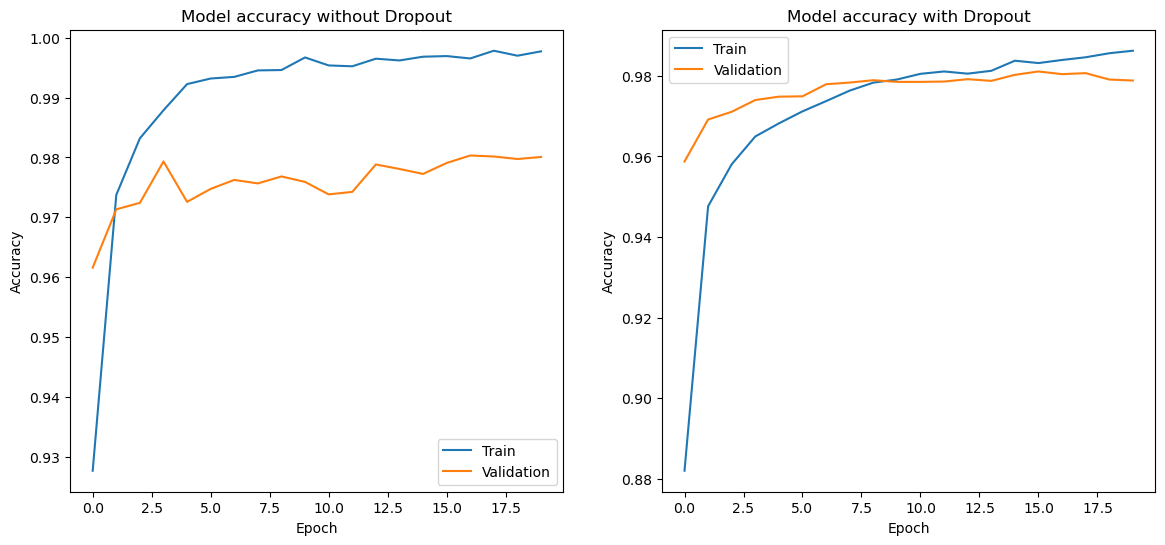

In [7]:
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.plot(history_without_dropout.history['accuracy'], label='Train')
plt.plot(history_without_dropout.history['val_accuracy'], label='Validation')
plt.title('Model accuracy without Dropout')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history_with_dropout.history['accuracy'], label='Train')
plt.plot(history_with_dropout.history['val_accuracy'], label='Validation')
plt.title('Model accuracy with Dropout')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.show()